# Автоматические признаки для прогноза следующего временного пакета

Основное сравнение — 48 ручных признаков без текущего канала взаимодействия
и 462 признака DFS. Прежние варианты 42/49 оставлены как история.
Report читает готовые результаты. Recompute повторяет подготовку и обучения;
новая оценка test включается через INCLUDE_TEST.


## Что проверяю

Хочу понять, можно ли автоматически получить признаки с качеством,
близким к сильному ручному набору, и сколько стоит их расчёт.

Основные варианты используют CatBoostRanker на одних целевых строках:

- **Ручные без текущего канала (48):** признаки трека, user-item, user-artist
  и общей истории пользователя; текущий is_organic исключён.
- **Автоматические DFS (462):** формулы по связанным таблицам, окна и свежесть.

Прежние ручные модели с 42 и 49 входами содержали текущий is_organic.
Их числа показывают ход исследования, но главным считаю сравнение без этого поля.
В файлах временной протокол сохранён под ID C4.


## Данные и метки

В Yambda flat 50m есть прослушивания, реакции и сведения о треках.
Готовой релевантности 0/1/2 нет, поэтому использую правила по порядку:

| label | Правило |
| --- | --- |
| 2 | Есть привязанный like |
| 0 | Иначе: есть dislike или прослушано менее 35% длины трека |
| 1 | Остальные прослушивания |

Реакцию привязываю к ближайшему следующему окончанию той же пары user-item,
если она попала в восстановленный интервал. Like имеет приоритет над
dislike. Unlike и undislike напрямую метку не задают.

Это приближение релевантности. Короткое прослушивание не всегда означает,
что пользователю не понравился трек.

## Как устроено время запроса

Для каждого пользователя объединяю прослушивания с одинаковым исходным timestamp
в один пакет. Для следующего пакета время запроса `t` — предыдущий **строго меньший**
timestamp пользователя. Первый пакет не участвует в оценке.

```text
исходные timestamp пользователя:       100       120       150
                                          запрос t=120 → target-пакет 150
доступная история: timestamp < 120     пакет 100
исключены на границе:                  пакет 120
предсказываемые события:               пакет 150
```

Окно имеет вид `[t - window, t)`. Пакет прямо на границе `t` не входит в историю.
События с одинаковым историческим timestamp упорядочиваются по неизменному ID
строки источника. Это технический порядок, а не известная последовательность внутри временного бина.

Текущее `played_ratio`, `label` и восстановленное начало не входят в признаки.
Строка исключается, если любой привязанный к целевому прослушиванию like/dislike
уже произошёл раньше `t`.

В исходном восстановленном начале нашлась утечка текущего исхода
через свежесть. Здесь cutoff взят из прошлого журнала. Старое start_ts
сохранилось только в правиле привязки реакций для разметки.


### Разбиение и кандидаты

| Часть | Время запроса, дни с нуля | Дополнительное условие |
| --- | --- | --- |
| Train | `[225, 270)` | Конец целевого прослушивания раньше `270 * DAY - 1800` |
| Validation | `[270, 285)` | Конец целевого прослушивания раньше `285 * DAY - 1800` |
| Повторный test | От 285 до конца журнала | Целевой пакет наблюдался; конечного GAP нет |

Обучение использует 40 000 целых смешанных по label user-day групп, выбранных
с seed 42. Это 2 021 867 целевых строк. Исторические события для расчёта признаков
сохраняются полностью, а не ограничиваются выбранными обучающими строками.
Validation и test включают все допустимые смешанные группы.

Группа — пользователь и день времени запроса. Кандидаты — наблюдавшиеся
прослушивания этого user-day, в том числе с разными `t`. Это вспомогательное
ранжирование наблюдавшихся событий: оно не оценивает одну выдачу или полный каталог.
История обновляется по мере поступления событий в validation/test; веса модели фиксированы.

In [1]:
from pathlib import Path
import json
import os
import sys

import pandas as pd
from IPython.display import display

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / 'task_1/src').is_dir() and (path / 'docs/results').is_dir())
TASK = ROOT / 'task_1'
sys.path.insert(0, str(TASK / 'src'))
from notebook_workflow import from_environment

MODE = os.getenv('TLAB_NOTEBOOK_MODE', 'report')  # report или recompute
RUN_NAME = os.getenv('TLAB_NOTEBOOK_RUN', 'repeat_01')
DOWNLOAD_DATA = os.getenv('TLAB_NOTEBOOK_DOWNLOAD', '1') == '1'
INCLUDE_TEST = os.getenv('TLAB_INCLUDE_TEST', '0') == '1'
workflow = from_environment(MODE, RUN_NAME, DOWNLOAD_DATA, INCLUDE_TEST)

import matplotlib.pyplot as plt
workflow.ensure('corrected')
workflow.ensure('feature-analysis')
if workflow.test_available:
    workflow.ensure('corrected-test')
REPORTS = ROOT / 'docs/results/c4'
TRAIN_RESULTS = workflow.path('corrected')
TEST_RESULTS = workflow.path('corrected-test')
FEATURE_REPORTS = workflow.path('feature-analysis')
workflow.ensure('channel-control')
CHANNEL_RESULTS = workflow.path('channel-control')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})


In [2]:
if MODE == 'report':
    validation = pd.read_csv(REPORTS / 'validation_comparison.csv', float_precision='round_trip')
    validation_intervals = pd.read_csv(REPORTS / 'validation_intervals.csv', float_precision='round_trip')
    test = pd.read_csv(REPORTS / 'test_comparison.csv', float_precision='round_trip')
    test_intervals = pd.read_csv(REPORTS / 'test_intervals.csv', float_precision='round_trip')
else:
    validation = pd.read_csv(TRAIN_RESULTS / 'comparison.csv', float_precision='round_trip')
    validation_intervals = pd.read_csv(TRAIN_RESULTS / 'bootstrap_summary.csv', float_precision='round_trip')
    test = pd.read_csv(TEST_RESULTS / 'comparison.csv', float_precision='round_trip') if INCLUDE_TEST else None
    test_intervals = pd.read_csv(TEST_RESULTS / 'bootstrap_summary.csv', float_precision='round_trip') if INCLUDE_TEST else None
control = json.loads((CHANNEL_RESULTS / 'result.json').read_text())
assert control['completed'] is True
control_comparison = pd.read_csv(CHANNEL_RESULTS / 'comparison.csv', float_precision='round_trip')
control_intervals = pd.read_csv(CHANNEL_RESULTS / 'bootstrap_summary.csv', float_precision='round_trip')
control_id = 'manual48_no_current_channel'
control_validation = control_comparison.loc[
    (control_comparison['variant'] == control_id) & (control_comparison['split'] == 'validation')]
assert len(control_validation) == 1
validation = pd.concat([validation, control_validation], ignore_index=True)
validation_intervals = pd.concat([
    validation_intervals, control_intervals.loc[control_intervals['split'] == 'validation']], ignore_index=True)
if test is not None:
    control_test = control_comparison.loc[
        (control_comparison['variant'] == control_id) & (control_comparison['split'] == 'test')]
    assert len(control_test) == 1
    test = pd.concat([test, control_test], ignore_index=True)
    test_intervals = pd.concat([
        test_intervals, control_intervals.loc[control_intervals['split'] == 'test']], ignore_index=True)

model_names = {'M-t': 'Исходные ручные (42)', 'C2b-t': 'Расширенные ручные (49)',
               control_id: 'Ручные без текущего канала (48)', 'D462-t': 'Автоматические DFS (462)'}
model_order = list(model_names)
validation = validation.set_index('variant').loc[model_order].reset_index()
assert validation['active_features'].tolist() == [42, 49, 48, 462]
assert validation['rows'].nunique() == validation['groups'].nunique() == 1
if test is not None:
    test = test.set_index('variant').loc[model_order].reset_index()
    assert test['rows'].nunique() == test['groups'].nunique() == 1

main_order = [control_id, 'D462-t']
historical_order = ['M-t', 'C2b-t']


## Признаки и модель

**Исходные ручные (42)**: `is_organic`, длина трека и 40 исторических признаков.

| Связь | Примеры |
| --- | --- |
| Item | Прослушивания, skip-rate, like-rate и средняя доля прослушивания; окна 1/7/30/90 дней |
| User-item | Счётчики прослушиваний и пропусков, затухание, свежесть и состояние like/unlike |
| User-artist | Счётчики прослушиваний и пропусков, затухание по исполнителю |

**Расширенные ручные (49)** добавляют долю прослушивания и skip последнего
доступного трека, skip-rate последних 5 и 20 событий, skip-rate и число событий
за сутки, время с последнего события пользователя.

Связи user-item и user-artist уже были в исходном наборе. Добавляются
признаки общей истории пользователя, без ограничения одним треком или исполнителем.
Это расширение появилось после DFS: автоматический поиск помог заметить,
что исходному набору не хватало общей истории пользователя.

**Контроль без текущего канала (48).** Текущий is_organic описывает канал
следующего фактического события; его доступность при t не обоснована.
Из расширенной модели исключён только этот вход. Остальные признаки,
строки, train-пороги, параметры и seed сохранены. Исторический is_organic
в доступных событиях остаётся. Этот дополнительный контроль уже выполнен
в отдельной проверке; здесь загружаются его готовые результаты.


**Автоматические DFS (462).** [Featuretools](https://docs.featuretools.com/en/stable/generated/featuretools.dfs.html) составляет формулы по таблицам
Users, Items, UserItem и UserArtist. Есть агрегаты, их сочетания, окна 1–30 дней,
полная история и свежесть. Всего получено 12 782 кандидата.
Значения считает накопительный движок, который поддерживает эту грамматику.
Числовые поля исходной истории — label, track_length_seconds и is_organic.
Исторический played_ratio_pct напрямую в грамматику не включён, тогда как
ручные признаки используют его среднее и последнее значение. Поэтому здесь
сравниваются конкретные представления, а не максимально сильный вариант DFS.

В прежнем протоколе отбор шёл на 9 999 train-строках (183 группы) и
5 000 validation-строках (96 групп). Признаки сортировались по train LossFunctionChange,
а k выбиралось по validation NDCG. Лучшим остался полный набор.
Затем отдельно взял 462 входа, использованные в разбиениях широкой модели из 91 дерева,
и переобучил модель на них. То есть `k=462` не было результатом первого top-k поиска.

В основное сравнение перенесён этот же список. **Нового отбора на исправленном
временном протоколе не было.** Здесь проверяю перенесённый набор,
а не весь поиск признаков с нуля.

В выбранные 462 входа вошли только исторические формулы. Текущие is_organic
и длина трека были среди кандидатов, но в этот набор не вошли. В ручных
вариантах 42/49 используются оба атрибута; в контроле 48 — только длина
трека, которую трактую как доступный атрибут каталога.

Все четыре варианта используют CatBoostRanker с YetiRank: depth 6, learning rate 0.1,
seed 42, до 1600 деревьев, early stopping 80 и четыре потока. Параметры перенесены
из прежних контролей, нового Optuna-поиска после исправления протокола не было.
Пороги квантования обучены заново только на общей train-подвыборке.

Основная метрика — **NDCG@10** с линейной релевантностью 0/1/2,
дополнительная — **QueryAUC Ranking**. Группы с постоянной меткой исключены.
Внешний расчёт NDCG разрешает точные ничьи общей фиксированной перестановкой
с seed 42. Встроенная метрика для early stopping обрабатывает ничьи иначе.

## Основное сравнение: ручные48 и DFS462

Обе модели оцениваются на одинаковых целевых строках. Контроль без текущего
канала обучался отдельно с низким приоритетом во время других расчётов,
поэтому его время fit не измеряет чистую разницу скорости методов.


In [3]:
comparison = validation.set_index('variant')[['active_features', 'NDCG@10', 'QueryAUC', 'fit_seconds', 'tree_count']]
comparison = comparison.rename(columns={'NDCG@10': 'Validation NDCG@10', 'QueryAUC': 'Validation QueryAUC'})
if test is not None:
    comparison['Повторный test NDCG@10'] = test.set_index('variant')['NDCG@10']
    comparison['Повторный test QueryAUC'] = test.set_index('variant')['QueryAUC']
comparison['Fit, мин'] = comparison.pop('fit_seconds') / 60
comparison = comparison.rename(columns={'active_features': 'Признаков', 'tree_count': 'Деревьев'})
display(comparison.loc[main_order].rename(index=model_names).round(6))


sizes = [{'Часть': 'Validation', 'Строк': validation['rows'].iloc[0], 'User-day групп': validation['groups'].iloc[0]}]
if test is not None:
    sizes.append({'Часть': 'Test', 'Строк': test['rows'].iloc[0], 'User-day групп': test['groups'].iloc[0]})
display(pd.DataFrame(sizes))


,Признаков,Validation NDCG@10,Validation QueryAUC,Деревьев,Повторный test NDCG@10,Повторный test QueryAUC,"Fit, мин"
variant,,,,,,,
Ручные без текущего канала (48),48,0.804589,0.677678,911,0.808769,0.677053,17.838850
Автоматические DFS (462),462,0.804623,0.676805,1043,0.808187,0.676752,26.727076


,Часть,Строк,User-day групп
0,Validation,2879535,57097
1,Test,3160068,61964


### Разница с DFS

Соединю метрики основных вариантов со строкой DFS каждого split.
Абсолютная разница — ручные48 минус DFS; относительная — её отношение к NDCG DFS.


In [4]:
scores = validation.loc[validation['variant'].isin(main_order)].assign(split='Validation')
if test is not None:
    scores = pd.concat([
        scores, test.loc[test['variant'].isin(main_order)].assign(split='Повторный test')], ignore_index=True)
reference = scores.loc[scores['variant'] == 'D462-t', ['split', 'NDCG@10']]
reference = reference.rename(columns={'NDCG@10': 'dfs_ndcg'})
deltas = scores[['split', 'variant', 'NDCG@10']].merge(reference, on='split', validate='many_to_one')
deltas['Абсолютная разница'] = deltas['NDCG@10'] - deltas['dfs_ndcg']
deltas['Прирост, %'] = 100 * deltas['Абсолютная разница'] / deltas['dfs_ndcg']
display(deltas.replace({'variant': model_names}).drop(columns='dfs_ndcg').round(6))


,split,variant,NDCG@10,Абсолютная разница,"Прирост, %"
0,Validation,Ручные без текущего канала (48),0.804589,-0.000034,-0.004248
1,Validation,Автоматические DFS (462),0.804623,0.000000,0.000000
2,Повторный test,Ручные без текущего канала (48),0.808769,0.000582,0.072009
3,Повторный test,Автоматические DFS (462),0.808187,0.000000,0.000000


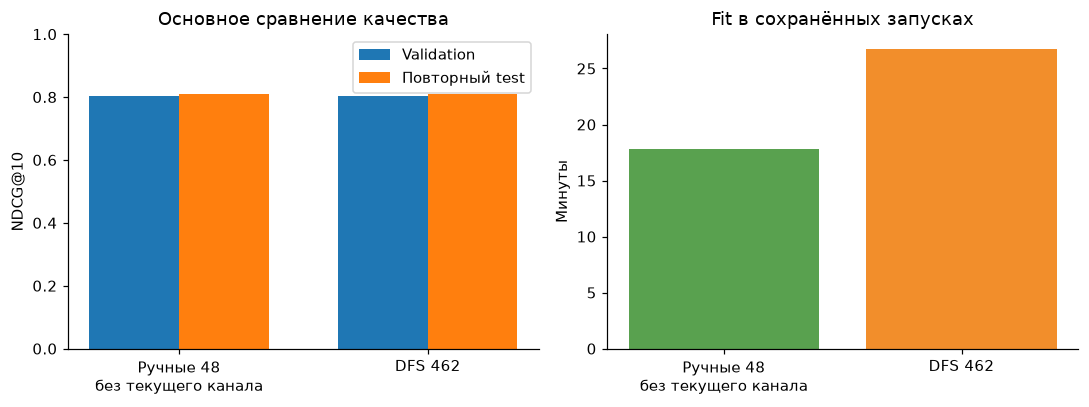

In [5]:
short_names = ['Ручные 48\nбез текущего канала', 'DFS 462']
main_validation = validation.set_index('variant').loc[main_order]
main_test = test.set_index('variant').loc[main_order] if test is not None else None
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
x = list(range(len(main_order)))
axes[0].bar([value - 0.18 for value in x], main_validation['NDCG@10'], width=0.36, label='Validation')
if main_test is not None:
    axes[0].bar([value + 0.18 for value in x], main_test['NDCG@10'], width=0.36, label='Повторный test')
axes[0].set(ylabel='NDCG@10', ylim=(0, 1), title='Основное сравнение качества')
axes[0].legend()
axes[1].bar(x, main_validation['fit_seconds'] / 60, color=['#59a14f', '#f28e2b'])
axes[1].set(ylabel='Минуты', title='Fit в сохранённых запусках')
for ax in axes:
    ax.set_xticks(x, short_names)
fig.tight_layout()
plt.show()


Ручные48 уступают DFS на 0.000034 NDCG на validation и выше на 0.000582
на ранее открытом test. Исключение текущего канала из прежней модели49
изменило NDCG на -0.000306 и -0.000271 соответственно.


## Парные интервалы разницы NDCG

Циклический блочный bootstrap по дням: блоки 3/4 дня, 20 000 повторов,
seed 42, двусторонние 95% percentile-интервалы. Обе модели получают
одинаковые дни; сохраняется вес user-day групп. Разница абсолютная.


In [6]:
main_pairs = {(control_id, 'D462-t'): 'Ручные без текущего канала 48 − DFS'}
historical_pairs = {
    ('D462-t', 'M-t'): 'DFS − исходные ручные 42',
    ('C2b-t', 'M-t'): 'Ручные 49 − исходные ручные 42',
    ('C2b-t', 'D462-t'): 'Ручные 49 − DFS',
}

def interval_table(intervals, pairs):
    '''Показать оба размера блока для выбранных пар.'''
    rows = []
    for pair, title in pairs.items():
        selected = intervals[(intervals['candidate'] == pair[0]) & (intervals['reference'] == pair[1])]
        row = {'Пара': title, 'Δ NDCG': selected['delta_ndcg'].iloc[0]}
        for block in (3, 4):
            values = selected.loc[selected['block_days'] == block].iloc[0]
            row[f'95% CI, {block} дня'] = f"[{values['ci_low']:+.6f}; {values['ci_high']:+.6f}]"
        rows.append(row)
    return pd.DataFrame(rows).set_index('Пара')

print('Validation: основное сравнение')
display(interval_table(validation_intervals, main_pairs).round(6))
if test_intervals is not None:
    print('Повторный test: основное сравнение')
    display(interval_table(test_intervals, main_pairs).round(6))


Validation: основное сравнение


,Δ NDCG,"95% CI, 3 дня","95% CI, 4 дня"
Пара,,,
Ручные без текущего канала 48 − DFS,-0.000034,[-0.001220; +0.001134],[-0.001171; +0.001101]


Повторный test: основное сравнение


,Δ NDCG,"95% CI, 3 дня","95% CI, 4 дня"
Пара,,,
Ручные без текущего канала 48 − DFS,0.000582,[+0.000008; +0.001144],[+0.000032; +0.001001]


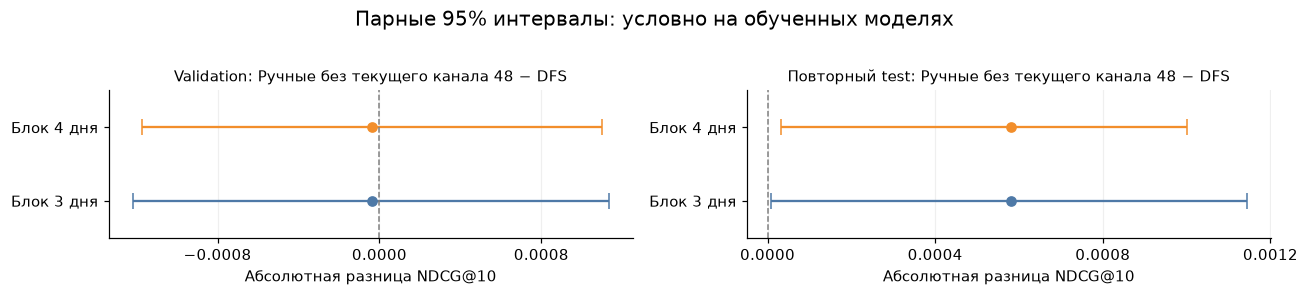

In [7]:
from plot_final_intervals import plot_intervals

plot_pairs = [(candidate, reference, title) for (candidate, reference), title in main_pairs.items()]
figure = plot_intervals(validation_intervals, test_intervals, pairs=plot_pairs)
plt.show()


Для ручного набора без текущего канала интервалы разницы с DFS включают
ноль на validation. На ранее открытом test они положительны; точечная
разница составляет +0.000582 NDCG@10. Для блока 3 дня нижняя граница
около +0.000008, для 4 дней — +0.000032.

Это условные интервалы готовых моделей, а не доказательство эквивалентности
или устойчивого превосходства между обучениями. Проверен один seed,
в validation 15 дней, в test 16; test уже использовался ранее.


## История: ручные42/49 и затраты первоначального запуска

Обе прежние ручные модели содержат текущий is_organic. Их метрики и интервалы
оставлены отдельно от основного сравнения 48–DFS.

Первоначальный train/validation для трёх моделей занял 67.04 минуты:
признаки и проверки 9.26, квантование 3.72, сумма fit 52.19.
Пик anonymous RAM — 5.74 GiB.


Соберу отдельные замеры генерации из отчётов. Ручные варианты используют
одну матрицу из 49 столбцов; исходная модель игнорирует семь из них, а контроль без текущего канала —
только is_organic. Новая генерация признаков для этого контроля не требовалась. Время
предсказания взято из сохранённой оценки, модели здесь не загружаются.


In [8]:
display(comparison.loc[historical_order].rename(index=model_names).round(6))
print('Прежние сравнения: validation')
display(interval_table(validation_intervals, historical_pairs).round(6))
if test_intervals is not None:
    print('Прежние сравнения: повторный test')
    display(interval_table(test_intervals, historical_pairs).round(6))

generation = []
for schema, title in [('manual', 'Ручные 49'), ('dfs', 'DFS 462')]:
    row = {'Признаки': title}
    for split, label in [('train', 'Train, с'), ('val', 'Validation, с')]:
        report = json.loads((TRAIN_RESULTS / f'generation_{schema}_{split}.json').read_text())
        row[label] = report['elapsed_seconds']
    if test is not None:
        report = json.loads((TEST_RESULTS / f'generation_{schema}_test.json').read_text())
        row['Test, с'] = report['elapsed_seconds']
        variant = 'C2b-t' if schema == 'manual' else 'D462-t'
        row['Предсказание test, с'] = test.set_index('variant').loc[variant, 'predict_seconds']
    generation.append(row)
generation = pd.DataFrame(generation).set_index('Признаки')
display(generation.round(3))
ratio = generation.loc['DFS 462'] / generation.loc['Ручные 49']
display(ratio.rename('DFS / ручные').round(2).to_frame())


,Признаков,Validation NDCG@10,Validation QueryAUC,Деревьев,Повторный test NDCG@10,Повторный test QueryAUC,"Fit, мин"
variant,,,,,,,
Исходные ручные (42),42,0.768964,0.607890,791,0.771547,0.604659,13.427811
Расширенные ручные (49),49,0.804896,0.678479,685,0.809040,0.678198,12.032637


Прежние сравнения: validation


,Δ NDCG,"95% CI, 3 дня","95% CI, 4 дня"
Пара,,,
DFS − исходные ручные 42,0.035660,[+0.034721; +0.036555],[+0.034737; +0.036497]
Ручные 49 − исходные ручные 42,0.035932,[+0.034839; +0.037168],[+0.034757; +0.037190]
Ручные 49 − DFS,0.000272,[-0.000782; +0.001345],[-0.000710; +0.001317]


Прежние сравнения: повторный test


,Δ NDCG,"95% CI, 3 дня","95% CI, 4 дня"
Пара,,,
DFS − исходные ручные 42,0.036640,[+0.035678; +0.037642],[+0.035622; +0.037652]
Ручные 49 − исходные ручные 42,0.037493,[+0.036403; +0.038619],[+0.036425; +0.038668]
Ручные 49 − DFS,0.000853,[+0.000173; +0.001539],[+0.000315; +0.001302]


,"Train, с","Validation, с","Test, с","Предсказание test, с"
Признаки,,,,
Ручные 49,47.974,64.435,52.335,0.219
DFS 462,188.104,234.238,244.543,0.673


,DFS / ручные
"Train, с",3.92
"Validation, с",3.64
"Test, с",4.67
"Предсказание test, с",3.08


## Что входит в 462 признака

Разберу сущности, окна и операции выбранного набора.
PredictionValuesChange описывает изменение предсказаний модели.
Важности сохранены при обучении.


In [9]:
selected_features = pd.read_csv(FEATURE_REPORTS / 'selected_features.csv')
entity_summary = pd.read_csv(FEATURE_REPORTS / 'entity_summary.csv')
window_summary = pd.read_csv(FEATURE_REPORTS / 'window_summary.csv')
operation_summary = pd.read_csv(FEATURE_REPORTS / 'operation_summary.csv')
top_features = pd.read_csv(FEATURE_REPORTS / 'top_features.csv')
feature_provenance = json.loads((FEATURE_REPORTS / 'provenance.json').read_text())

assert len(selected_features) == 462
assert selected_features['feature'].is_unique
print(f'Выбранных входов: {len(selected_features)}')
print(f"Суммарная сохранённая важность: {selected_features['importance'].sum():.6f}")
assert feature_provenance['importance_type'] == 'PredictionValuesChange'
assert feature_provenance['internal_variant'] == 'D462-t'
assert feature_provenance['feature_count'] == len(selected_features)
assert all(table['feature_count'].sum() == len(selected_features)
           for table in (entity_summary, window_summary, operation_summary))

Выбранных входов: 462
Суммарная сохранённая важность: 100.000000


### Сущности и операции

Сопоставим количество формул и сумму их важностей.


In [10]:
entity_table = entity_summary[['entity_label', 'feature_count', 'importance_sum']].rename(columns={
    'entity_label': 'Связь', 'feature_count': 'Число формул', 'importance_sum': 'Сумма важностей',
})
operation_table = operation_summary[['operation_label', 'feature_count', 'importance_sum']].rename(columns={
    'operation_label': 'Тип формулы', 'feature_count': 'Число формул', 'importance_sum': 'Сумма важностей',
})
display(entity_table.round(3))
display(operation_table.round(3))

,Связь,Число формул,Сумма важностей
0,Пользователь,132,50.209
1,Трек,148,15.692
2,Пользователь–трек,59,21.778
3,Пользователь–исполнитель,123,12.320


,Тип формулы,Число формул,Сумма важностей
0,Один агрегат,52,18.974
1,Произведение двух агрегатов,349,56.638
2,Агрегат произведения полей события,56,6.659
3,Давность первого/последнего события,5,17.729


### Временные окна

В поиске участвовали окна 1–30 дней. Покажу состав перенесённого набора
и его использование итоговой моделью. Соседние окна пересекаются.


,История,Число формул,Сумма важностей
0,Вся доступная история,51,38.555


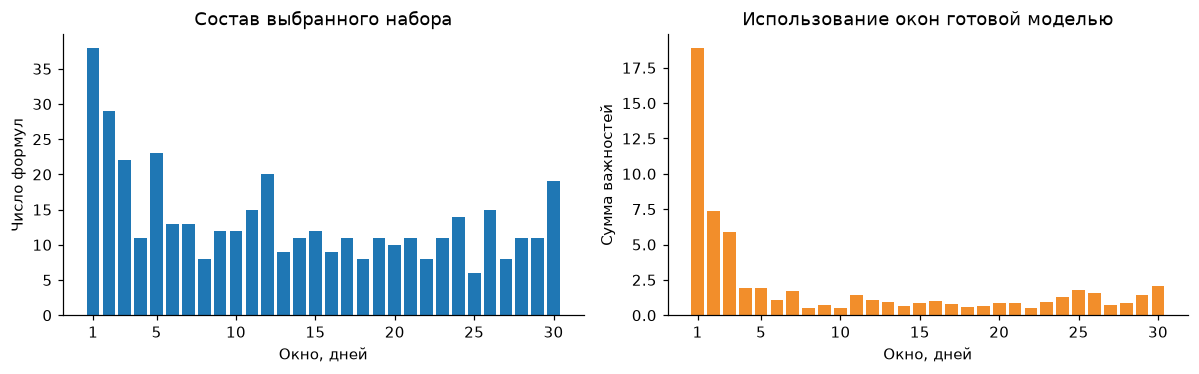

In [11]:
# Давности входят в полную историю, без ограничения окна.
full_history = window_summary[window_summary['window_days'].isna()]
display(full_history[['window_label', 'feature_count', 'importance_sum']].rename(columns={
    'window_label': 'История', 'feature_count': 'Число формул', 'importance_sum': 'Сумма важностей',
}).round(3))

windows = window_summary[window_summary['window_days'].notna()]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].bar(windows['window_days'], windows['feature_count'])
axes[0].set(ylabel='Число формул', title='Состав выбранного набора')
axes[1].bar(windows['window_days'], windows['importance_sum'], color='#f28e2b')
axes[1].set(ylabel='Сумма важностей', title='Использование окон готовой моделью')
for ax in axes:
    ax.set(xlabel='Окно, дней', xticks=[1, 5, 10, 15, 20, 25, 30])
fig.tight_layout()
plt.show()

### Примеры важных формул

Для каждой формулы показаны связь, окно и смысл.
Средний label пары User–Item считается по её доступным прошлым событиям.


In [12]:
top_columns = ['importance_rank', 'feature', 'entity_label', 'window_label', 'importance', 'explanation']
top_table = top_features.head(10)[top_columns].rename(columns={
    'importance_rank': 'Место', 'feature': 'Формула', 'entity_label': 'Связь',
    'window_label': 'Окно', 'importance': 'Важность', 'explanation': 'Смысл',
})
with pd.option_context('display.max_colwidth', 100):
    display(top_table.round({'Важность': 4}))

,Место,Формула,Связь,Окно,Важность,Смысл
0,1,"Users__TIME_SINCE_LAST(Interactions.end_ts, unit=days)",Пользователь,Вся доступная история,14.2126,Пользователь: дней с последнего доступного взаимодействия; вся доступная история.
1,2,"Users__MAX(Interactions.label, Last 1 Days) * MEAN(Interactions.label, Last 1 Days)",Пользователь,1 дн.,7.0347,Пользователь: (максимум(историческая метка) × среднее(историческая метка)); 1 дн.
2,3,UserItem__MEAN(Interactions.label),Пользователь–трек,Вся доступная история,6.7125,Пользователь–трек: среднее(историческая метка); вся доступная история.
3,4,"Users__MEAN(Interactions.label, Last 3 Days)",Пользователь,3 дн.,3.6373,Пользователь: среднее(историческая метка); 3 дн.
4,5,"Users__COUNT(Interactions, Last 2 Days) * MEAN(Interactions.label, Last 2 Days)",Пользователь,2 дн.,2.0083,Пользователь: (число взаимодействий × среднее(историческая метка)); 2 дн.
5,6,UserItem__COUNT(Interactions) * MEAN(Interactions.label),Пользователь–трек,Вся доступная история,1.7417,Пользователь–трек: (число взаимодействий × среднее(историческая метка)); вся доступная история.
6,7,"Users__COUNT(Interactions, Last 1 Days)",Пользователь,1 дн.,1.6797,Пользователь: число взаимодействий; 1 дн.
7,8,"Users__MAX(Interactions.track_length_seconds, Last 1 Days) * MEAN(Interactions.label, Last 1 Days)",Пользователь,1 дн.,1.5344,Пользователь: (максимум(длина трека) × среднее(историческая метка)); 1 дн.
8,9,"Users__COUNT(Interactions, Last 1 Days) * MIN(Interactions.label, Last 1 Days)",Пользователь,1 дн.,1.2844,Пользователь: (число взаимодействий × минимум(историческая метка)); 1 дн.
9,10,"UserItem__TIME_SINCE_FIRST(Interactions.end_ts, unit=days)",Пользователь–трек,Вся доступная история,1.1332,Пользователь–трек: дней с первого доступного взаимодействия; вся доступная история.


## Вывод и ограничения

DFS помог получить полезные признаки общей истории пользователя.
Расширенный ручной набор сохранил близкое качество после исключения
текущего канала взаимодействия. Превосходство проверенного DFS-462 над
этим ручным набором не подтвердилось.

- Контроль с 48 входами относится к расширенной модели. Исходная модель
  с 42 входами по-прежнему содержит текущий is_organic; контроль 41 не проводился.
- Метки эвристические; семантика timestamp и доступность атрибутов каталога заданы допущениями.
- Оценка ранжирует наблюдавшиеся смешанные по меткам user-day группы.
- 462 формулы перенесены из прежнего поиска. Validation и test использовались повторно.
- Один seed и условные интервалы не описывают все повторные обучения и временные окна.

Независимый повтор исходного C4-сравнения подтвердил побайтное совпадение
шести матриц manual49/DFS462 и всех validation/test-прогнозов трёх новых моделей.
Контроль48 также проверен на заново построенном test Pool.
Полные исторические Optuna и временные окна не повторялись.
[Проверка основного расчёта](../../docs/results/reproduction/main_verification.json).


## Где посмотреть детали

- [Основной README](../../README.md).
- [Прогноз следующего временного пакета](../../docs/c4.md).
- [Повторная оценка моделей](../../docs/c4-test.md).
- [Выбранные признаки](../../docs/feature-analysis.md).
- [Проверка восстановленного начала](../../docs/start-time-audit.md).
- [Установка и пересчёт](../../docs/reproduction.md).

Ранние ноутбуки оставлены как история исследования. Их метрики нельзя
парно сравнить с текущими: после смены времени запроса изменились
строки, группы и доступная история.